In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)

import tensorflow as tf
from tensorflow.keras.callbacks import TensorBoard

print(tf.config.list_physical_devices('GPU'))


import numpy as np
from tqdm import tqdm
import datetime

from data_loaders.data_loader_complete import DataLoaderComplete
import project_images_loader as pil

import discriminator as Discriminator
import generator as Generator

import feature_extractor as feature_extractor

import utils.functions as fc
import utils.util_deep_learning as udl
import utils.util as util
import utils.visualization as vis
import utils.util_freesurfer_segmentation as ufs


tf.keras.backend.set_image_data_format("channels_first")
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')



2024-04-30 20:18:36.773264: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-04-30 20:18:42.859276: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
SERVER: True


## Visualize data

In [2]:
def get_weight_mask_hunt4(data_train, weights, dtype=np.float32):
    # transform = lambda x: np.where(x > 0, 1, 0)
    transform = None
    _, bmask_hunt4 = data_train.get_iter_custom_images(pil.INAME_BRAIN_MASK.format("{0}", "{1}", pil.REGISTRATION_TO_MNI), dtype)
    _, seg_hunt4 = data_train.get_iter_custom_images(pil.INAME_SEGMENTATION.format("{0}", "{1}", 3, "nii.gz"), dtype, transform)
    weigth_mask = np.zeros(bmask_hunt4.shape, dtype=dtype)
    for i in range(len(weigth_mask)):
        weigth_mask[i] = ufs.get_4_tissues_prob_mask(bmask_hunt4[i,0], seg_hunt4[i,0], weights)
    return weigth_mask


In [3]:
# %matplotlib widget

# data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED,
#                                 batch_size=1, 
#                                 image_size=(192, 224, 192), 
#                                 channels_first=True,
#                                 shuffle=True, 
#                                 nb_patients=10, 
#                                 shuffle_before_selecting=False, 
#                                 server=False,
#                                 start_from=0)

# batch_h3, batch_h4 = data_train[0]
# weights={"bg":0, "ext":0.5, "csf":2, "gm":3, "wm":1}
# weigth_mask = get_weight_mask_hunt4(data_train, weights)
# print(data_train.get_iter_ids())
# fc.imgshow_3D("", batch_h4[0,0])
# fc.imgshow_3D("", weigth_mask[0,0])


### Validation visualization

In [4]:
def show_generated_image(id, G, current_plane=116, show=True, img_size=(192, 224, 192), img_offset=(0,0,0)):
    
    img_hunt3 = pil.load_preprocessed_image(3, id, absolute=True)[0]
    img_hunt4 = pil.load_preprocessed_image(4, id, absolute=True)[0]

    img_gen_h4 = G(udl.prepare_img_for_gan(img_hunt3, axis_channels=1, img_size=img_size, img_offset=img_offset), training=False)
    img_gen_h4 = udl.recover_img_from_gan(img_gen_h4, axis_channels=1, img_offset=img_offset)
    return vis.shows_3_images(img_hunt3, img_hunt4, img_gen_h4, current_plane=current_plane, show=show)



### Loss functions

In [5]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=False)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    total_loss = (real_loss + fake_loss)/2
    return total_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def feature_extractor_loss(Fe, h4_real, h4_fake):
    feat_h4_real_list = Fe(h4_real, training=False)
    feat_h4_fake_list = Fe(h4_fake, training=False)

    loss = tf.constant(0.0, dtype=tf.float16)
    for i in range(len(feat_h4_real_list)):
        loss += tf.reduce_mean(tf.abs(feat_h4_real_list[i] - feat_h4_fake_list[i]))
    loss /= len(feat_h4_real_list)
    return tf.cast(loss, tf.float32)

def voxel_loss(h4_real, h4_fake, weigth_mask_hunt4):
    return tf.reduce_mean( tf.abs((h4_real - h4_fake) * weigth_mask_hunt4)) 





In [6]:
@tf.function
def train_step(G, D, Fe, h3_batch, h4_batch, g_optimizer, d_optimizer, weigth_mask_hunt4):
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        h4_fake = G(h3_batch, training=True)

        real_output = D(h4_batch, training=True)
        fake_output = D(h4_fake, training=True)

        _gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

        l1_loss = voxel_loss(h4_batch, h4_fake, weigth_mask_hunt4)
        percetual_loss = feature_extractor_loss(Fe, h4_batch, h4_fake)

        gen_loss = _gen_loss + 25.0 * l1_loss + 25.0 * percetual_loss 


    gradients_of_generator = gen_tape.gradient(gen_loss, G.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, D.trainable_variables)

    g_optimizer.apply_gradients(zip(gradients_of_generator, G.trainable_variables))
    d_optimizer.apply_gradients(zip(gradients_of_discriminator, D.trainable_variables))

    return gen_loss, disc_loss, l1_loss, percetual_loss



### Training

2024-04-30 20:19:09.838492: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1928] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15520 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:82:00.0, compute capability: 6.0



Epoch 1/1000


2024-04-30 20:19:17.173793: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


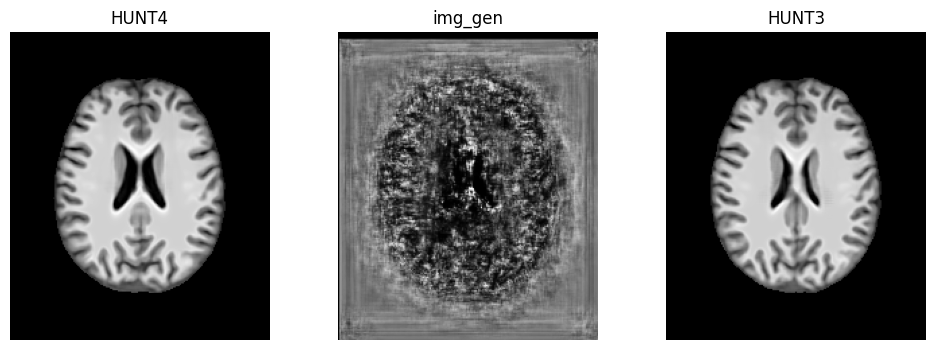

Initializing...:   0%|          | 0/155 [00:00<?, ?it/s]/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.10/site-packages/tensorflow/python/framework/tensor_util.py:504: RuntimeWarning: overflow encountered in cast
  nparray = values.astype(dtype.as_numpy_dtype)
gen_loss: 9.93211	disc_loss: 0.55623	l1_loss: 0.03670	percetual_loss: 0.31623:  26%|██▋       | 41/155 [01:45<02:53,  1.52s/it]  

In [7]:

def train(num_epochs, batch_size, monitor_each, show=False):
    # input_shape = (193,229,193)
    # input_shape = (192,224,192)
    input_shape = (192,224, 16)
    img_offset = (0,0,110)
    current_plane = 116

    # ---- Models
    D = Discriminator.create_discriminator_model(input_shape)
    G = Generator.create_generator_model(input_shape)
    Fe = feature_extractor.create_features_extractor((1,)+input_shape, pil.get_genesis_weights_path_name())
    # Freeze features extractor layers
    # udl.freeze_layers(Fe, -1)

    # optimizers
    inital_lr = 1e-4
    g_optimizer = tf.keras.optimizers.Adam(inital_lr)
    d_optimizer = tf.keras.optimizers.Adam(inital_lr)

    g_optimizer_monitor = udl.LearningRateMonitor(g_optimizer, inital_lr, 0.5, 1e-10, 10, "loss")
    d_optimizer_monitor = udl.LearningRateMonitor(d_optimizer, inital_lr, 0.5, 1e-10, 10, "loss")

    # ---- Data
    server = False
    data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED,
                                    batch_size=batch_size, 
                                    image_size=input_shape, 
                                    channels_first=True,
                                    shuffle=True, 
                                    nb_patients=620//4, 
                                    shuffle_before_selecting=False, 
                                    exclude_ids=["08202"],
                                    server=server,
                                    data_type=np.float32,
                                    img_size_offset=img_offset)
    weights={"bg":0, "ext":0.5, "csf":1.2, "gm":1.2, "wm":1.0}
    # visualization
    nb_loss = 4
    acum_loss_train = udl.AcumulativeMetrics(nb_metrics = nb_loss)

    log_dir = f"{current_path}/models/logs/train" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    summary_writer = tf.summary.create_file_writer(log_dir)

    # ---- checkpoint
    checkpoint_dir = f"{current_path}/models/training_checkpoints/"
    checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
    checkpoint = tf.train.Checkpoint(g_optimizer=g_optimizer,
                                     d_optimizer=d_optimizer,
                                    G=G,
                                    D=D)
    # restore checkpoint
    checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))

    for epoch in range(0,num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        
        # visualize images
        if epoch == 0 and show:
            show_generated_image("08202", G, current_plane=current_plane, show=show, img_size=input_shape, img_offset=img_offset)
        
        # ---- Train
        acum_loss_train.reset()
        progress_bar = tqdm(total=len(data_train), desc=f'Initializing...')
        for step, (h3_batch, h4_batch) in enumerate(data_train):
            weigth_mask_hunt4 = get_weight_mask_hunt4(data_train, weights)
            
            gen_loss, disc_loss, l1_loss, percetual_loss = train_step(G, D, Fe, h3_batch, h4_batch, g_optimizer, d_optimizer, weigth_mask_hunt4)
            acum_loss_train.update((gen_loss, disc_loss, l1_loss, percetual_loss))
            losses_text = acum_loss_train.get_progress_bar_text(['gen_loss', 'disc_loss', 'l1_loss', 'percetual_loss'])

            progress_bar.set_description(desc=losses_text)
            progress_bar.update(1)
        del progress_bar

        loss_mean = acum_loss_train.get_mean()

        g_optimizer_monitor.on_epoch_end(loss_mean[0])
        d_optimizer_monitor.on_epoch_end(loss_mean[1])

        if (epoch + 1) % monitor_each == 0:
            # ---- Check points
            checkpoint.save(file_prefix=checkpoint_prefix)

            val_results = show_generated_image("08202", G, current_plane=current_plane, show=show, img_size=input_shape, img_offset=img_offset)


            # ---- tensorboard
            with summary_writer.as_default():
                tf.summary.scalar('gen_loss', loss_mean[0], step=epoch)
                tf.summary.scalar('disc_loss', loss_mean[1], step=epoch)
                tf.summary.scalar('l1_loss', loss_mean[2], step=epoch)
                tf.summary.scalar('percetual_loss', loss_mean[3], step=epoch)

                # images
                gen_image_h4 = np.expand_dims(np.expand_dims(val_results[2], axis=-1), axis=0)
                hunt4_vs_gen_h4 = np.expand_dims(np.stack([val_results[2], val_results[1], np.zeros_like(val_results[1])], axis=-1), axis=0)
                tf.summary.image("generated H4", gen_image_h4, step=epoch)
                tf.summary.image("R: Gen H4 - G: HUNT4", hunt4_vs_gen_h4, step=epoch)
        

train(num_epochs=1000, batch_size=1, monitor_each=1, show=True)
# lat check point 12

In [ ]:
# Sim: 0.00000 	 gen_loss: 0.93415 	 disc_loss: 1.11709: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]
# Sim: 0.00000 	 gen_loss: 1.22538 	 disc_loss: 1.64933: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]